# ResNet18 Baseline Result Analysis

This notebook analyzes the first binary baseline trained on the APTOS 2019 dataset.
The goal is to visualize and document the main evaluation results before moving to Grad-CAM.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, load_fundus_records, default_transforms
from dr_detection.train import build_model

config = load_yaml_config(project_root / "configs" / "default.yaml")
dataset_cfg = config["dataset"]
training_cfg = config["training"]

checkpoint_path = project_root / "models" / "best_model.pt"
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

label_map = {0: "No DR", 1: "DR Present"}

test_records = load_fundus_records(
    csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
    images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
    image_extension=dataset_cfg.get("image_extension", ".png"),
    binary_classification=dataset_cfg.get("binary_classification", True),
)

test_dataset = FundusImageDataset(
    test_records,
    transform=default_transforms(image_size=dataset_cfg.get("image_size", 224), train=False),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=training_cfg.get("batch_size", 16),
    shuffle=False,
    num_workers=0,
)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

checkpoint = torch.load(checkpoint_path, map_location=device)
model = build_model(
    model_name=checkpoint["model_name"],
    num_classes=checkpoint["num_classes"],
    pretrained=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print(f"Checkpoint: {checkpoint_path}")
print(f"Device: {device}")
print(f"Test size: {len(test_dataset)}")


Checkpoint: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/models/best_model.pt
Device: mps
Test size: 366


In [3]:
all_labels = []
all_predictions = []
all_scores = []
all_image_paths = []

with torch.no_grad():
    for images, labels, image_paths in test_loader:
        images = images.to(device)
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_scores.extend(probabilities[:, 1].cpu().tolist())
        all_image_paths.extend(image_paths)

predictions_df = pd.DataFrame(
    {
        "image_path": all_image_paths,
        "true_label": all_labels,
        "predicted_label": all_predictions,
        "dr_probability": all_scores,
    }
)
predictions_df["true_class"] = predictions_df["true_label"].map(label_map)
predictions_df["predicted_class"] = predictions_df["predicted_label"].map(label_map)
predictions_df["correct"] = predictions_df["true_label"] == predictions_df["predicted_label"]

predictions_df.head()


,image_path,true_label,predicted_label,dr_probability,true_class,predicted_class,correct
0,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,0.041322,No DR,No DR,True
1,/Users/berekebaimuratov/Desktop/Detection of D...,1,1,1.000000,DR Present,DR Present,True
2,/Users/berekebaimuratov/Desktop/Detection of D...,1,1,1.000000,DR Present,DR Present,True
3,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,0.114621,No DR,No DR,True
4,/Users/berekebaimuratov/Desktop/Detection of D...,0,0,0.006416,No DR,No DR,True


**Table 2.1. Final test-set metrics for the ResNet18 binary baseline**


In [4]:
metrics_df = pd.DataFrame(
    {
        "metric": ["accuracy", "precision", "recall", "f1_score", "roc_auc"],
        "value": [
            accuracy_score(all_labels, all_predictions),
            precision_score(all_labels, all_predictions, zero_division=0),
            recall_score(all_labels, all_predictions, zero_division=0),
            f1_score(all_labels, all_predictions, zero_division=0),
            roc_auc_score(all_labels, all_scores),
        ],
    }
)
metrics_df["value"] = metrics_df["value"].round(4)

metrics_df.to_csv(figures_dir / "table_2_1_test_metrics.csv", index=False)
metrics_df


,metric,value
0,accuracy,0.9781
1,precision,0.9649
2,recall,0.9880
3,f1_score,0.9763
4,roc_auc,0.9974


**Table 2.2. Confusion-matrix counts for the test split**


In [5]:
cm = confusion_matrix(all_labels, all_predictions)
tn, fp, fn, tp = cm.ravel()

cm_counts_df = pd.DataFrame(
    {
        "outcome": ["True Negative", "False Positive", "False Negative", "True Positive"],
        "count": [tn, fp, fn, tp],
    }
)
cm_counts_df.to_csv(figures_dir / "table_2_2_confusion_counts.csv", index=False)
cm_counts_df


,outcome,count
0,True Negative,193
1,False Positive,6
2,False Negative,2
3,True Positive,165


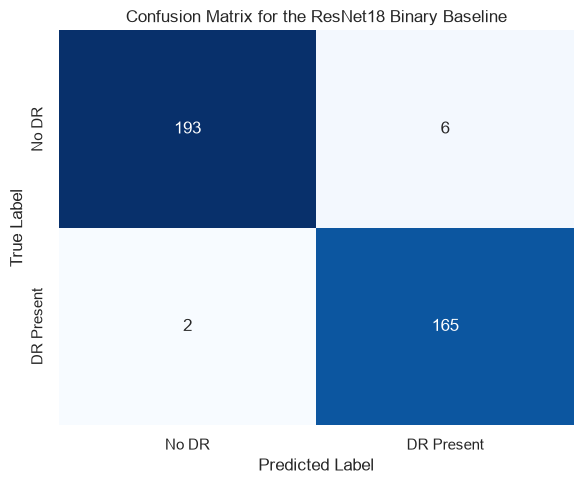

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[label_map[0], label_map[1]],
    yticklabels=[label_map[0], label_map[1]],
    ax=ax,
)
ax.set_title("Confusion Matrix for the ResNet18 Binary Baseline")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.tight_layout()
fig.savefig(figures_dir / "figure_2_1_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 2.1. Confusion matrix for the ResNet18 binary baseline on the APTOS 2019 test split**


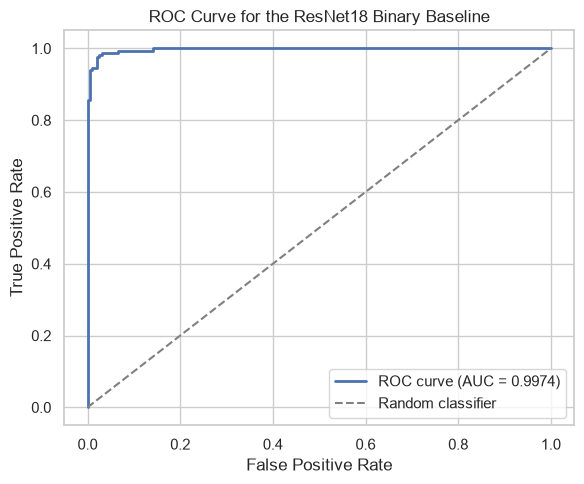

In [7]:
fpr, tpr, _ = roc_curve(all_labels, all_scores)
roc_auc = roc_auc_score(all_labels, all_scores)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, linewidth=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("ROC Curve for the ResNet18 Binary Baseline")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(figures_dir / "figure_2_2_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 2.2. ROC curve for the ResNet18 binary baseline on the APTOS 2019 test split**


**Image 2.1. Misclassified retinal fundus images from the test split**


In [8]:
misclassified_df = predictions_df.loc[~predictions_df["correct"]].copy()
misclassified_df = misclassified_df.sort_values("dr_probability", ascending=False).reset_index(drop=True)

misclassified_df.head(10)


,image_path,true_label,predicted_label,dr_probability,true_class,predicted_class,correct
0,/Users/berekebaimuratov/Desktop/Detection of D...,0,1,0.999598,No DR,DR Present,False
1,/Users/berekebaimuratov/Desktop/Detection of D...,0,1,0.985237,No DR,DR Present,False
2,/Users/berekebaimuratov/Desktop/Detection of D...,0,1,0.979482,No DR,DR Present,False
3,/Users/berekebaimuratov/Desktop/Detection of D...,0,1,0.965454,No DR,DR Present,False
4,/Users/berekebaimuratov/Desktop/Detection of D...,0,1,0.672468,No DR,DR Present,False
5,/Users/berekebaimuratov/Desktop/Detection of D...,0,1,0.546390,No DR,DR Present,False
6,/Users/berekebaimuratov/Desktop/Detection of D...,1,0,0.234854,DR Present,No DR,False
7,/Users/berekebaimuratov/Desktop/Detection of D...,1,0,0.068883,DR Present,No DR,False


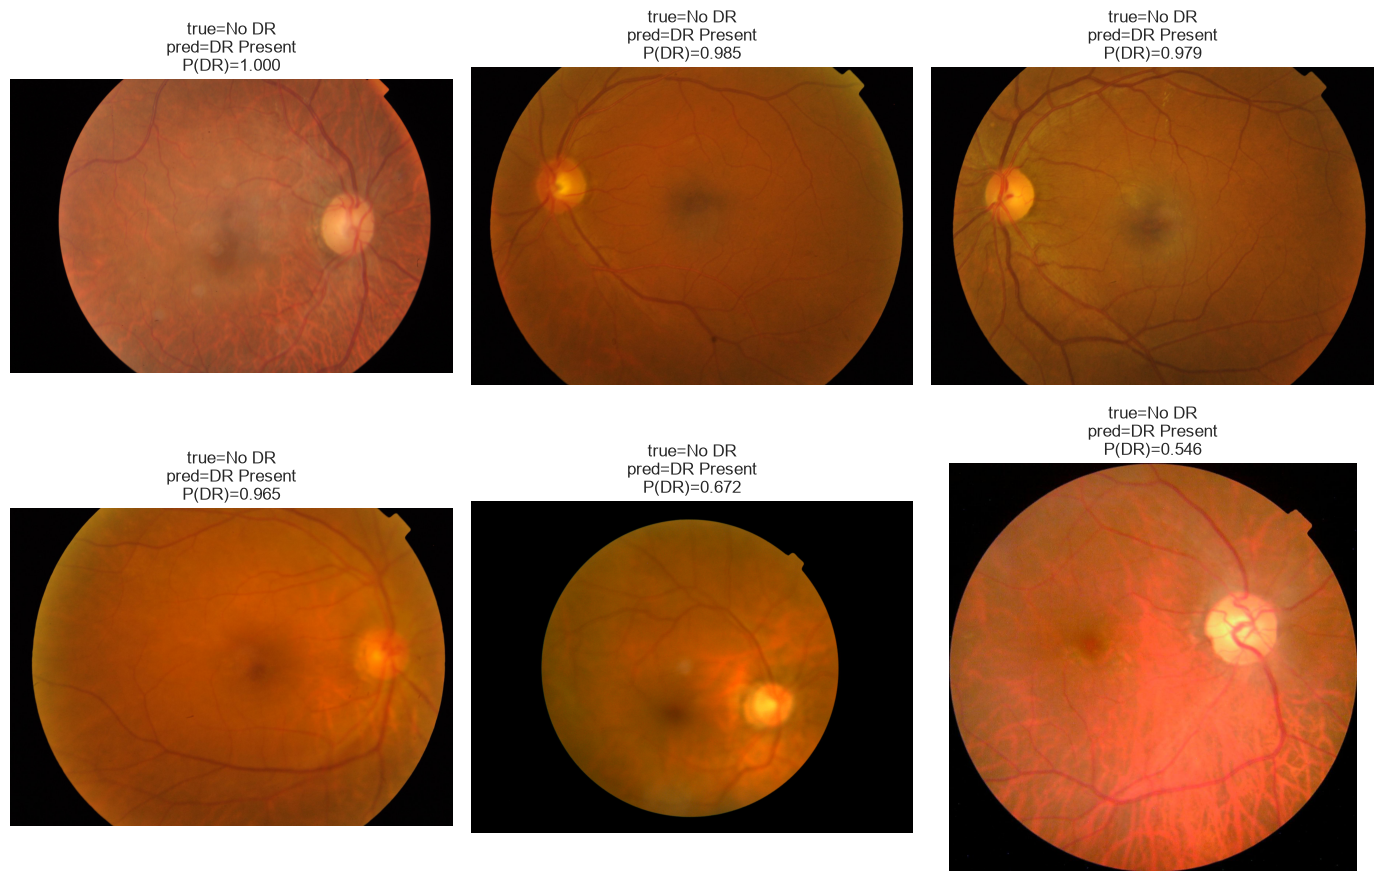

In [9]:
def show_misclassified_examples(df: pd.DataFrame, n: int = 6) -> None:
    sample_df = df.head(min(n, len(df))).reset_index(drop=True)
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, sample_df.iterrows()):
        image = Image.open(row["image_path"]).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"true={row['true_class']}\n"
            f"pred={row['predicted_class']}\n"
            f"P(DR)={row['dr_probability']:.3f}"
        )
        ax.axis("off")

    for ax in axes[len(sample_df):]:
        ax.axis("off")

    plt.tight_layout()
    fig.savefig(figures_dir / "image_2_1_misclassified_examples.png", dpi=300, bbox_inches="tight")
    plt.show()


show_misclassified_examples(misclassified_df)


## Interpretation

This notebook confirms that the first ResNet18 baseline performs strongly on the binary classification task.
The next step is to combine these quantitative results with explainability analysis using Grad-CAM.
